# Diagnose plate-position effects in the validation plates

In the screen, where a well sits on the plate shifts its profile in a consistent, feature-specific direction (a "tilt") that has nothing to do with what is in the well (`../../../4.image_based_profiling/3a.position_correction/`).
Before we call hits on the validation plates, we ask whether they show the same effect.

The validation plates have one layout of 60 wells (rows B to G and columns 2 to 11), repeated on five replicate plates, except for the compounds:

- 36 DMSO wells at the same positions on every plate, in blocks of columns that cover all six rows: 18 failing (heart 25) in columns 2, 4, and 10, and 18 non-failing (non-failing, heart 7) in columns 3, 9, and 11;
- 24 compound wells in columns 5 to 8 (all six rows), on failing cells (heart 25).
  Each plate holds three compounds, each in 8 wells, and each of the 15 compounds is on one plate only, so the compound wells are not replicated.

Because the DMSO wells repeat at the same positions on all five plates, they are the part of the layout that measures position: a DMSO position that differs from the other positions of its cell type differs because of where it is.

**Questions**

1. How much of the variation between wells depends on the plate row and column?
2. Is this a position effect, and not the effect of the cell type or of the compounds?
3. Is it associated with the number of cells in the well?

**Input**

- `<plate>_sc_normalized.parquet` of the five validation plates (step 2 of this module, `../2.single_cell_processing.ipynb`): QC-passing single cells, standardized on each plate.
  By default the notebook reads them from bandicoot; set `VALIDATION_PROFILE_DIR` to read another folder.

**Output** (in this folder)

- `well_medians.parquet`: the median profile of every well of every plate (a cache that git ignores).
- `figures/diagnostics/`: the figures below.

**Method**

We summarize every well as the median profile of its cells and follow the screen's diagnostics (`../../../4.image_based_profiling/3a.position_correction/2.effect_on_feature_space.ipynb`):
principal components of the wells, and the fraction of each component that plate row explains (the "eta squared" of the row groups).
We repeat it on the DMSO wells of one cell type at a time, so that the cell type and the compounds cannot drive the result.

## Import libraries

In [1]:
import os
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../../../utils")
import position_correction_effect_utils as pce
import position_correction_utils as pcu
import validation_position_utils as vpu

## Set paths and parameters

In [2]:
# folder with the <plate>_sc_normalized.parquet files (only read when the well cache is missing:
# an existing well_medians.parquet is used whatever this folder is, so delete it when the profiles change)
profile_dir = pathlib.Path(
    os.environ.get(
        "VALIDATION_PROFILE_DIR",
        "~/mnt/bandicoot/CFReT_screening_data/validation_profiles/single_cell_profiles",
    )
).expanduser()
n_jobs = int(os.environ.get("N_JOBS", "4"))

# plate maps, which give the plate number of every plate
platemap_dir = pathlib.Path("../../metadata/platemaps")

output_dir = pathlib.Path(".")
figure_dir = output_dir / "figures" / "diagnostics"
figure_dir.mkdir(parents=True, exist_ok=True)

# well summary is cached because reading the five plates takes a few minutes
well_medians_cache = output_dir / "well_medians.parquet"

min_cells = 50  # minimum cells for a well to be used (as in the screen)
n_components = 10  # principal components to report
random_state = 0  # seed of the PCA, so the components are reproducible

# one color per plate row, B (top of the plate) to G
row_colors = plt.cm.viridis(np.linspace(1, 0, pcu.N_ROW_TERMS))

## Summarize every well

Each well becomes the median profile of its cells.
Features with a missing value in any well are dropped, because the tilt fit cannot use them.

In [3]:
well_medians, features = vpu.load_or_build_well_medians(
    well_medians_cache, profile_dir, n_jobs=n_jobs, platemap_dir=platemap_dir
)

well_medians["row"], well_medians["col"] = pcu.well_index(well_medians["well"])
is_nonfailing = (well_medians["treatment"] == "DMSO") & (
    well_medians["cell_type"] == vpu.NONFAILING_CELL_TYPE
)
is_failing = (well_medians["treatment"] == "DMSO") & (
    well_medians["cell_type"] == vpu.FAILING_CELL_TYPE
)
well_medians["kind"] = np.select(
    [is_nonfailing, is_failing], ["non-failing DMSO", "failing DMSO"], "compound"
)

print("Plates:", well_medians["plate"].nunique())
print("Wells per plate:", well_medians.groupby("plate").size().unique())
print("Features:", len(features))
print(well_medians["kind"].value_counts().to_dict())
print(
    "Cells per well (min, median, max):",
    well_medians["n"].min(),
    int(well_medians["n"].median()),
    well_medians["n"].max(),
)

Plates: 5
Wells per plate: [60]
Features: 2453
{'compound': 120, 'failing DMSO': 90, 'non-failing DMSO': 90}
Cells per well (min, median, max): 59 225 351


## Layout check

The non-failing and the failing DMSO should sit at identical positions on every plate and cover several rows and columns, so that position can be told apart from the cell type.
The compounds are on one plate each, in columns 5 to 8.
The first table lists the rows of the DMSO wells, and the second the wells of the compounds of the first plate.

In [4]:
plates = sorted(well_medians["plate"].unique())
dmso_layout = well_medians[well_medians["kind"] != "compound"]
# the positions of each cell type of DMSO on every plate (a plate that swapped the two cell types at the
# same wells would have the same set of DMSO wells, so the two kinds are compared one by one)
positions = dmso_layout.groupby(["kind", "plate"])["well"].apply(lambda wells: tuple(sorted(wells)))
print(
    "DMSO positions of each cell type identical on all plates:",
    bool((positions.groupby("kind").nunique() == 1).all() and positions.groupby("kind").size().eq(len(plates)).all()),
)
print(
    pd.crosstab(
        dmso_layout[dmso_layout["plate"] == plates[0]]["kind"],
        dmso_layout[dmso_layout["plate"] == plates[0]]["well"].str[0],
    ).to_string()
)
print()
first_plate_compounds = well_medians[
    (well_medians["plate"] == plates[0]) & (well_medians["kind"] == "compound")
]
print(
    first_plate_compounds.groupby("treatment")["well"]
    .apply(lambda wells: " ".join(sorted(wells)))
    .to_string()
)
print(
    "\nCompound wells per row:",
    well_medians.loc[well_medians["kind"] == "compound", "well"].str[0].value_counts().sort_index().to_dict(),
)
print("Plates of each compound:", well_medians.loc[well_medians["kind"] == "compound"].groupby("treatment")["plate"].nunique().max(), "(at most)")

DMSO positions of each cell type identical on all plates: True
well              B  C  D  E  F  G
kind                              
failing DMSO      3  3  3  3  3  3
non-failing DMSO  3  3  3  3  3  3

treatment
K278    B07 C06 D05 D08 E07 F05 F08 G06
K310    B05 B08 C07 D06 E05 E08 F06 G07
K543    B06 C05 C08 D07 E06 F07 G05 G08

Compound wells per row: {'B': 20, 'C': 20, 'D': 20, 'E': 20, 'F': 20, 'G': 20}
Plates of each compound: 1 (at most)


## Principal components of the wells and plate position

We fit the principal components on the uncorrected wells.
For each component we report the fraction of its variance that each factor explains.
A factor with `k` groups explains about `(k - 1) / (n - 1)` of a component by chance.
With the 300 wells that is about 2% for the six rows and 3% for the ten columns; with the 90 wells of one kind of DMSO it is about 6% for the six rows and 2% for the three columns that the cell type occupies; with the 36 averaged positions of the last analysis it is about 14% for the six rows and 14% for the six columns that they occupy.
Values well above these mean structure.

- **Plate row and column:** the position.
- **Treatment group:** which compound, or the DMSO of which cell type, the well holds.
- **Plate:** which of the five replicate plates the well comes from.

We repeat the analysis four ways:

1. **All wells**, as in the screen.
2. **Failing DMSO wells only** (18 positions on 5 plates). One cell type and one treatment, so position is the only thing that varies between the positions.
3. **Non-failing DMSO wells only**, the same for the non-failing cells.
4. **DMSO wells without the cell-type effect.** We average the five plates, then subtract the mean profile of each cell type. What is left differs only between the positions of a cell type, so a row or column effect here cannot be an effect of the cell type.

In [5]:
wells = well_medians[well_medians["n"] >= min_cells].reset_index(drop=True)
# the treatment group: the compound, or the DMSO of one cell type (both are "DMSO" in the treatment column)
wells["treatment_group"] = np.where(wells["kind"] == "compound", wells["treatment"], wells["kind"])
all_table, all_pca, all_scores = pce.pc_variance_table(
    wells, wells[features].to_numpy(float), "all wells", n_components, random_state,
    factors=("row", "col", "plate", "treatment_group"),
)

failing_wells = wells[wells["kind"] == "failing DMSO"].reset_index(drop=True)
failing_table, _, _ = pce.pc_variance_table(
    failing_wells, failing_wells[features].to_numpy(float), "failing DMSO wells", n_components, random_state, factors=("row", "col", "plate")
)
nonfailing_wells = wells[wells["kind"] == "non-failing DMSO"].reset_index(drop=True)
nonfailing_table, _, _ = pce.pc_variance_table(
    nonfailing_wells, nonfailing_wells[features].to_numpy(float), "non-failing DMSO wells", n_components, random_state, factors=("row", "col", "plate")
)

# average the replicate plates of every DMSO well, then remove the mean of its cell type
dmso_wells = wells[wells["kind"] != "compound"].reset_index(drop=True)
averaged = dmso_wells.groupby(["kind", "well"])[features].mean().reset_index()
averaged["row"], averaged["col"] = pcu.well_index(averaged["well"])
within_profiles = averaged[features].to_numpy(float) - (
    averaged.groupby("kind")[features].transform("mean").to_numpy(float)
)
# the cell type and the plate cannot explain anything here: their effects are removed or averaged
within_table, _, _ = pce.pc_variance_table(
    averaged,
    within_profiles,
    "DMSO wells without the cell-type effect",
    n_components,
    random_state,
    factors=("row", "col"),
)

variance_by_position = pd.concat([all_table, failing_table, nonfailing_table, within_table])
for analysis, table in variance_by_position.groupby("analysis", sort=False):
    print(f"\n{analysis}")
    print(table.drop(columns="analysis").head(6).round(3).to_string(index=False))


all wells
component  variance_explained  row_explains  col_explains  plate_explains  treatment_group_explains
      PC1               0.479         0.532         0.200           0.003                     0.358
      PC2               0.152         0.060         0.271           0.007                     0.696
      PC3               0.077         0.078         0.138           0.004                     0.351
      PC4               0.050         0.077         0.051           0.020                     0.743
      PC5               0.045         0.123         0.042           0.002                     0.257
      PC6               0.025         0.025         0.169           0.024                     0.264

failing DMSO wells
component  variance_explained  row_explains  col_explains  plate_explains  treatment_group_explains
      PC1               0.543         0.692         0.070           0.041                       NaN
      PC2               0.176         0.076         0.024           0

## What do the components show?

The component that plate row explains most is the one to look at.
The left panels give the fraction of the first six components that plate row and plate column explain in the failing DMSO wells and in the DMSO wells without the cell-type effect; the right panel shows the number of cells per well by row, because the number of cells is a common cause of position effects (edge wells grow differently).

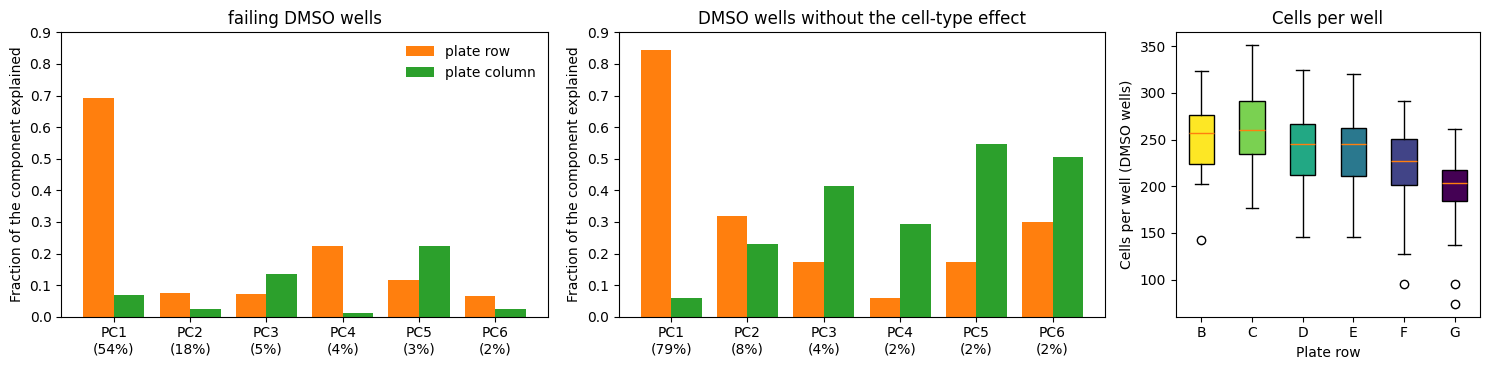

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.6, 1.6, 1]})
for ax, analysis in zip(
    axes[:2], ["failing DMSO wells", "DMSO wells without the cell-type effect"], strict=True
):
    table = variance_by_position[variance_by_position["analysis"] == analysis].head(6)
    x = np.arange(len(table))
    ax.bar(x - 0.2, table["row_explains"], width=0.4, label="plate row", color="tab:orange")
    ax.bar(x + 0.2, table["col_explains"], width=0.4, label="plate column", color="tab:green")
    ax.set_xticks(x, labels=[f"{c}\n({v:.0%})" for c, v in zip(table["component"], table["variance_explained"], strict=True)])
    ax.set_ylabel("Fraction of the component explained")
    ax.set_title(analysis)
    ax.set_ylim(0, 0.9)
axes[0].legend(frameon=False)
cells = [
    dmso_wells.loc[dmso_wells["row"] == r, "n"].to_numpy()
    for r in range(pcu.N_ROW_TERMS)
]
box = axes[2].boxplot(cells, tick_labels=list(pcu.ROWS), patch_artist=True)
for patch, color in zip(box["boxes"], row_colors, strict=True):
    patch.set_facecolor(color)
axes[2].set_xlabel("Plate row")
axes[2].set_ylabel("Cells per well (DMSO wells)")
axes[2].set_title("Cells per well")
fig.tight_layout()
fig.savefig(figure_dir / "row_column_variance_and_cell_counts.png", dpi=150)
plt.show()

In [7]:
cell_correlations = [
    np.corrcoef(all_scores[:, i], np.log(wells["n"]))[0, 1] for i in range(3)
]
print(
    "Correlation of PC1 to PC3 with log(cells per well), all wells:",
    np.round(cell_correlations, 2),
)

Correlation of PC1 to PC3 with log(cells per well), all wells: [-0.61 -0.32  0.  ]


## Is it the plate position or the number of cells?

The number of cells per well changes with the row, and the first component correlates with it.
Position and cell number can both be associated with a component, and the two are related (edge wells grow differently).
This comparison shows that each adds to the other as an association. It does not show that position acts through the cell number: the cell number could respond to position, or both could respond to something else.
For the first three components of the DMSO wells of each cell type, we compare how much of the component each explains alone (R squared of a linear model) and together.
If the row adds to the cell number (and the other way around), the two effects are not the same thing.
We repeat the comparison without the cell-type effect (five plates averaged, cell-type mean removed).

In [8]:
density = []
for label, subset in (("failing DMSO wells", failing_wells), ("non-failing DMSO wells", nonfailing_wells)):
    subset_pca = pce.fit_pca(subset[features].to_numpy(float), 3, random_state)
    density.append(
        pce.explained_by_position_and_cells(
            subset["row"].to_numpy(),
            np.log(subset["n"].to_numpy()),
            subset_pca.transform(subset[features].to_numpy(float)),
            label,
        )
    )

# plates averaged and the cell-type mean removed, as above
averaged_cells = (
    dmso_wells.assign(log_cells=np.log(dmso_wells["n"]))
    .groupby(["kind", "well"])["log_cells"]
    .mean()
    .reset_index()
)
within_cells = averaged_cells["log_cells"].to_numpy() - averaged_cells.groupby("kind")[
    "log_cells"
].transform("mean").to_numpy()
within_pca = pce.fit_pca(within_profiles, 3, random_state)
density.append(
    pce.explained_by_position_and_cells(
        averaged["row"].to_numpy(),
        within_cells,
        within_pca.transform(within_profiles),
        "DMSO wells without the cell-type effect",
    )
)
density = pd.concat(density)
print(density.round(2).to_string(index=False))

log_cells = np.log(dmso_wells["n"])
kind_share = 1 - (
    (log_cells - log_cells.groupby(dmso_wells["kind"]).transform("mean")) ** 2
).sum() / ((log_cells - log_cells.mean()) ** 2).sum()
print(
    f"\nShare of the variation in log cells per DMSO well that the cell type explains: {kind_share:.2f}"
)
print(
    "Correlation of the cell number (cell-type mean removed) with the plate row:",
    round(np.corrcoef(within_cells, averaged["row"])[0, 1], 2),
)
print(
    "Median cells per DMSO well by row:",
    dmso_wells.groupby(dmso_wells["row"].map(dict(enumerate(pcu.ROWS))))["n"].median().astype(int).to_dict(),
)

                               analysis component  row  log_cells  row_and_log_cells
                     failing DMSO wells       PC1 0.69       0.05               0.70
                     failing DMSO wells       PC2 0.08       0.02               0.09
                     failing DMSO wells       PC3 0.07       0.03               0.09
                 non-failing DMSO wells       PC1 0.76       0.33               0.81
                 non-failing DMSO wells       PC2 0.09       0.00               0.09
                 non-failing DMSO wells       PC3 0.10       0.12               0.23
DMSO wells without the cell-type effect       PC1 0.84       0.34               0.88
DMSO wells without the cell-type effect       PC2 0.32       0.03               0.32
DMSO wells without the cell-type effect       PC3 0.17       0.24               0.36

Share of the variation in log cells per DMSO well that the cell type explains: 0.00
Correlation of the cell number (cell-type mean removed) with the 

## The wells in the first two components

Each point is a well of a plate; the black outline marks the DMSO controls.
The left panel colors the wells by plate row and the right panel by plate column.
The principal components are the same as in the table above (all wells).

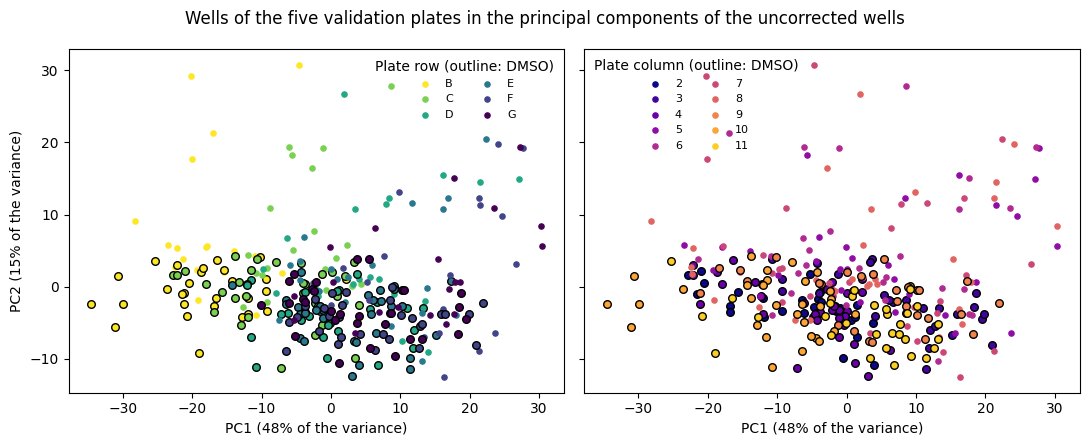

In [9]:
top_component = int(
    variance_by_position.query("analysis == 'all wells'")["row_explains"].to_numpy().argmax()
)
is_control = (wells["kind"] != "compound").to_numpy()
column_colors = plt.cm.plasma(np.linspace(0, 0.9, pcu.N_COL_TERMS + 1))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, factor, colors, names, title in [
    (axes[0], "row", row_colors, list(pcu.ROWS), "Plate row"),
    (axes[1], "col", column_colors, [str(c) for c in range(2, 12)], "Plate column"),
]:
    for level, name in enumerate(names):
        in_level = (wells[factor] == level).to_numpy()
        ax.scatter(
            all_scores[in_level & ~is_control, 0],
            all_scores[in_level & ~is_control, 1],
            s=14,
            color=colors[level],
            label=name,
        )
        ax.scatter(
            all_scores[in_level & is_control, 0],
            all_scores[in_level & is_control, 1],
            s=30,
            color=colors[level],
            edgecolor="black",
        )
    ax.set_xlabel(f"PC1 ({all_pca.explained_variance_ratio_[0]:.0%} of the variance)")
    ax.legend(frameon=False, ncol=2, fontsize=8, title=f"{title} (outline: DMSO)")
axes[0].set_ylabel(f"PC2 ({all_pca.explained_variance_ratio_[1]:.0%} of the variance)")
fig.suptitle("Wells of the five validation plates in the principal components of the uncorrected wells")
fig.tight_layout()
fig.savefig(figure_dir / "well_pca_by_row_and_column.png", dpi=150)
plt.show()

## The component that plate row explains most, on the plate layout

Each tile is the score of one well on the component that plate row explains most (a horizontal stripe is a plate-row effect, a vertical stripe a column effect).
The five left panels are the replicate plates, the last panel averages them.
Gray tiles hold no well on the plate or have too few cells.
The DMSO tiles repeat on all plates, so a pattern in them is a position effect; the compound tiles are a different set of compounds on each plate.

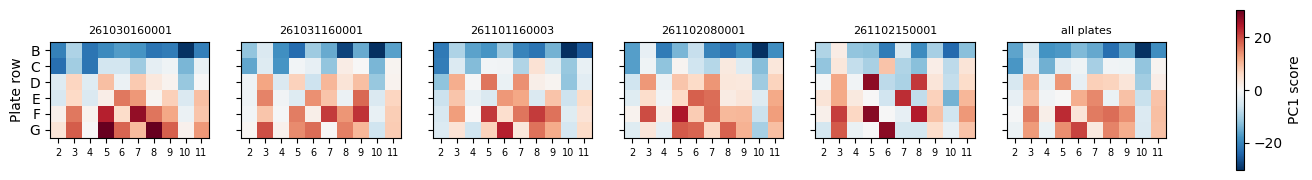

In [10]:
layout_scores = wells[["plate", "row", "col"]].assign(score=all_scores[:, top_component])
limit = np.abs(layout_scores["score"]).quantile(0.99)
fig, axes = plt.subplots(1, len(plates) + 1, figsize=(3 * (len(plates) + 1), 2.6), sharey=True)
for ax, plate in zip(axes, [*plates, "all plates"], strict=True):
    subset = layout_scores if plate == "all plates" else layout_scores[layout_scores["plate"] == plate]
    grid = subset.groupby(["row", "col"])["score"].mean().unstack().reindex(
        index=range(pcu.N_ROW_TERMS), columns=range(pcu.N_COL_TERMS + 1)
    )
    image = ax.imshow(grid, cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_xticks(range(10), labels=range(2, 12), fontsize=7)
    ax.set_title(plate.removeprefix("CARD-CelIns-CX7_") if plate != "all plates" else plate, fontsize=8)
axes[0].set_yticks(range(pcu.N_ROW_TERMS), labels=list(pcu.ROWS))
axes[0].set_ylabel("Plate row")
fig.colorbar(image, ax=axes, label=f"PC{top_component + 1} score", shrink=0.8)
fig.savefig(figure_dir / "plate_layout_top_row_pc.png", dpi=150, bbox_inches="tight")
plt.show()

## How to read this notebook

- A component that plate row explains much more than by chance in the DMSO wells of one cell type, and also **without the cell-type effect**, is a position effect.
- Non-failing and failing DMSO cover all six rows equally (three wells of each kind in every row of a plate), so a row effect cannot masquerade as the cell type.
  They sit in different blocks of columns, though, so a column effect is confounded with the cell type (and with the compounds, which are in columns 5 to 8): `1.fit_position_correction.ipynb` explains how the fit handles that.
- The number of cells per well changes with the row, and each adds to the other as an association with the first component.
  This is an association and not a pathway: it does not show that position acts through the cell number. A correction by position removes the part of the cell-number pattern that follows position too.
- The compounds are on one plate each, in columns 5 to 8, so no compound is replicated.
  The DMSO wells are the replicated positions, and every statement about position that needs replicates rests on them.